# 02. Exploratory Data Analysis & Feature Engineering

## Prerequisites

This notebook explores the interim table built by `transferformance.interim` (`data/interim/interim.parquet`): one row per player per valuation date, with the cleaning rules from `01_data_overview.ipynb` applied and the appearance statistics of the previous 365 days attached.

The end goal are to understand what drives Transfermarkt's market prediction and to turn those findings into the features and settings that will be used for modeling.

### Import libraries

In [22]:
from transferformance.configs import PATH_INTERIM_DATA

import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

import pyarrow as pa

In [2]:
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")

### Preparing the dataset

#### Import the dataset

First, we import the dataset that was built from the interim steps.

In [3]:
try:
    df_interim = pd.read_parquet(PATH_INTERIM_DATA)
except FileNotFoundError as err:
    raise f"{PATH_INTERIM_DATA} not found. Make sure that you run the pipeline before this: {err}"
except (pa.ArrowInvalid, OSError) as err:
    raise f"{PATH_INTERIM_DATA} is corrupted or undreadable: {err}"


print(f"Interim dataset's shape: {df_interim.shape}")

df_interim.head()

Interim dataset's shape: (217831, 18)


,player_id,date,market_value_in_eur,date_of_birth,position,height_in_cm,foot,n_appearances,minutes_per_365d,goals_per_365d,assists_per_365d,yellow_cards_per_365d,red_cards_per_365d,goals_conceded_per_365d,clean_sheets_per_365d,league_minutes_per_365d,cup_minutes_per_365d,league_id
0,114060,2019-12-20,1500000,1986-09-12,Attack,189,left,27,1951,5,1,5,0,35,4,1703,0,ES1
1,262523,2019-03-01,20000000,1996-12-06,Defender,176,right,34,2743,1,1,8,0,39,6,2034,180,IT1
2,167721,2019-06-11,5000000,1994-02-06,Attack,172,right,36,2166,10,2,14,0,66,2,1986,180,ES1
3,153065,2019-06-10,1700000,1992-02-27,Midfield,174,right,25,2071,4,1,3,0,40,2,2071,0,BE1
4,351816,2019-12-12,17000000,1997-12-01,Midfield,175,left,32,2664,0,1,10,0,55,6,2664,0,IT1


#### Splitting the dataset

Now that the dataset is loaded, we split it into training, validation and test sets.

The interim dataset is time-ordered. Each row is a market valuation on a given date, with statistics computed over the previous 365 days, and market values drift over time. 

A random split would let the model train on valuations from after the ones it is tested on. That is why we will be splitting by football season instead, which runs from the beginning of July to the end of June of the following year:

- **Train:** 11 seasons, from July 2013 to June 2024 (2013-14 to 2023-24).
- **Validation:** 1 season, from July 2024 to June 2025 (2024-25). Used for model selection and tuning.
- **Test:** 1 season, from July 2025 to June 2026 (2025-26, data until 2026-06-11). Evaluated once at the end.

The window features only look back from each valuation date, so they do not leak information across the cutoffs.

In [4]:
TRAIN_END = pd.to_datetime("2024-06-30").date()
VALID_END = pd.to_datetime("2025-06-30").date()

In [5]:
df_train = df_interim[df_interim["date"] <= TRAIN_END].copy()
df_valid = df_interim[
    (df_interim["date"] > TRAIN_END) & (df_interim["date"] <= VALID_END)
].copy()
df_test = df_interim[df_interim["date"] > VALID_END].copy()


print("Sets' statistic:")
for name, part in [
    ("Training set", df_train),
    ("Validation set", df_valid),
    ("Test set", df_test),
]:
    print(
        f'{name:<15} | {len(part):<6} | {100.0 * len(part) / len(df_interim):^8.2f} % | Min: {part["date"].min().strftime("%Y-%m-%d"):^15} | Max: {part["date"].max().strftime("%Y-%m-%d"):^15}'
    )

Sets' statistic:
Training set    | 178658 |  82.02   % | Min:   2013-07-05    | Max:   2024-06-30   
Validation set  | 18003  |   8.26   % | Min:   2024-07-01    | Max:   2025-06-30   
Test set        | 21170  |   9.72   % | Min:   2025-07-11    | Max:   2026-06-11   


To ensure that the validation and test sets remain completely unseen and unbiased, we will restrict exploratory data analysis on only the training set.

## Analysis

First, we check the basic statistics of the cleaned dataset.

In [6]:
df_train.describe()

,player_id,market_value_in_eur,height_in_cm,n_appearances,minutes_per_365d,goals_per_365d,assists_per_365d,yellow_cards_per_365d,red_cards_per_365d,goals_conceded_per_365d,clean_sheets_per_365d,league_minutes_per_365d,cup_minutes_per_365d
count,1.786580e+05,1.786580e+05,178658.000000,178658.000000,178658.000000,178658.000000,178658.000000,178658.000000,178658.000000,178658.000000,178658.000000,178658.000000,178658.000000
mean,2.353963e+05,4.566205e+06,182.316291,19.065046,1324.850368,1.920552,1.487619,2.810991,0.069972,25.903105,3.003493,1134.221899,122.032263
std,1.966870e+05,1.012530e+07,6.656781,12.704314,1047.157570,3.662661,2.451800,2.958306,0.269525,17.392996,3.781372,911.370961,201.037662
min,1.000000e+01,1.000000e+04,159.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7.486100e+04,4.250000e+05,178.000000,8.000000,386.250000,0.000000,0.000000,0.000000,0.000000,11.000000,0.000000,303.000000,0.000000
50%,1.869260e+05,1.000000e+06,183.000000,18.000000,1147.000000,0.000000,0.000000,2.000000,0.000000,25.000000,2.000000,990.000000,32.000000
75%,3.410490e+05,4.000000e+06,187.000000,29.000000,2088.000000,2.000000,2.000000,4.000000,0.000000,39.000000,5.000000,1825.000000,176.000000
max,1.247360e+06,2.000000e+08,207.000000,68.000000,5790.000000,61.000000,33.000000,24.000000,3.000000,108.000000,33.000000,4410.000000,2010.000000


### Distribution of `market_value_in_eur`

We examine the distribution of `market_value_in_eur`. Because player valuations range from tens of thousands to hundreds of millions of euros, the top valuations span several orders of magnitude. 

Comparing market_value_in_eur on linear vs. log scales highlights the heavy skewness and makes the underlying distribution far clearer.

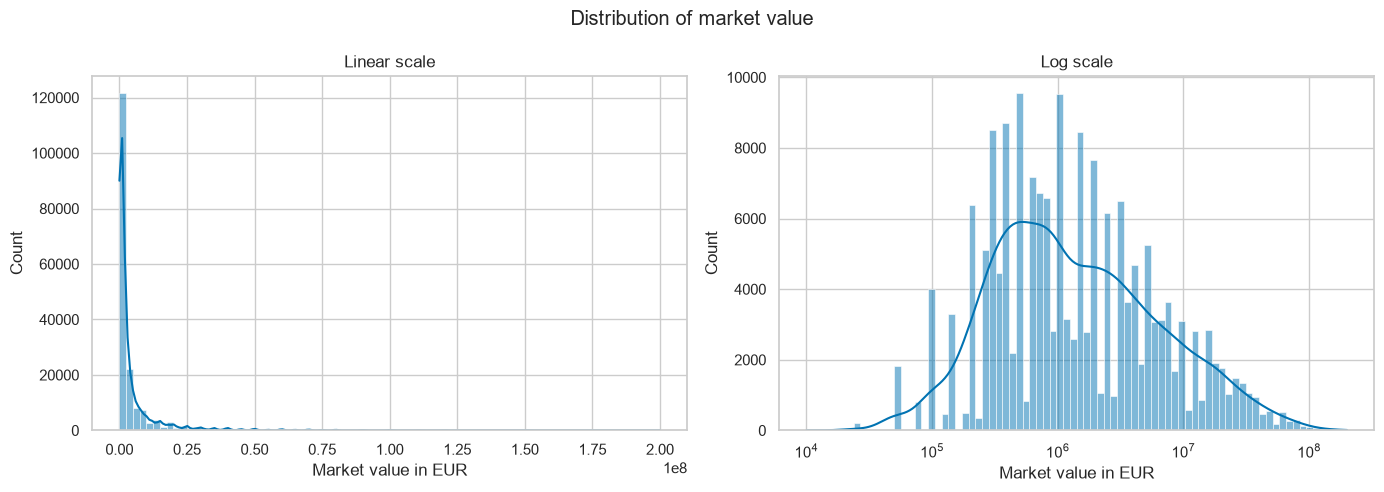

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plt.suptitle("Distribution of market value")

sns.histplot(data=df_train, x="market_value_in_eur", bins=80, ax=ax1, kde=True)
ax1.set_title("Linear scale")
ax1.set_xlabel("Market value in EUR")

sns.histplot(
    data=df_train,
    x="market_value_in_eur",
    log_scale=True,
    bins=80,
    ax=ax2,
    kde=True,
    kde_kws={"bw_adjust": 2.0},
)
ax2.set_title("Log scale")
ax2.set_xlabel("Market value in EUR")

plt.tight_layout()
plt.show()

**Observations:**

* On the linear scale, market value is extremely right-skewed, with most valuations concentrated at low values and a long tail extending up to 200M EUR.
* On the log scale, the distribution is multimodal, featuring a shoulder in the 1-10 million EUR range.
* The jagged shape on the log scale stems from valuations being recorded in discrete steps (e.g., 200k EUR, 250k EUR, 300k EUR).

In [ ]:
df_train["market_value_in_eur_log1p"] = np.log1p(df_train["market_value_in_eur"])

print(f"`market_value_in_eur`'s skewness: {df_train['market_value_in_eur'].skew():.3f}")
print(
    f"`market_value_in_eur_log1p`'s skewness: {df_train['market_value_in_eur_log1p'].skew():.3f}"
)

`market_value_in_eur`'s skewness: 5.635
`market_value_in_eur_log1p`'s skewness: 0.340


Looking at the results, raw `market_value_in_eur` is heavily skewed (5.635 > 3), while the log-transformed version `market_value_in_eur_log1p` has only a slight right skew (0.340).

**Decision:** Model `np.log1p(market_value_in_eur)` as the target. This resolves the extreme right-skewness so that errors are relative and top-valued players do not dominate training.

### Relation between `market_value_in_eur_log1p` and other features

#### Feature engineering: `season_start`

We defined a new feature named `season_start`, which gives the calendar year in which a football season began. 

Seasons run from roughly July to June, so dates from July onward (month >= 7) belong to the season that starts in that same year, while dates from January to June belong to the season that started the previous year. 

This lets us study how market value changes over time without splitting a season in half. It also helps us check whether the dataset covers all seasons evenly, which matters because market values change over time and a skewed distribution could bias the model toward the most common seasons.

In [9]:
df_train["season_start"] = np.where(
    pd.to_datetime(df_train["date"]).dt.month >= 7,
    pd.to_datetime(df_train["date"]).dt.year,
    pd.to_datetime(df_train["date"]).dt.year - 1,
)

Using the new `season_start` feature, we plot the number of player valuations per season to see how the data is distributed over time.

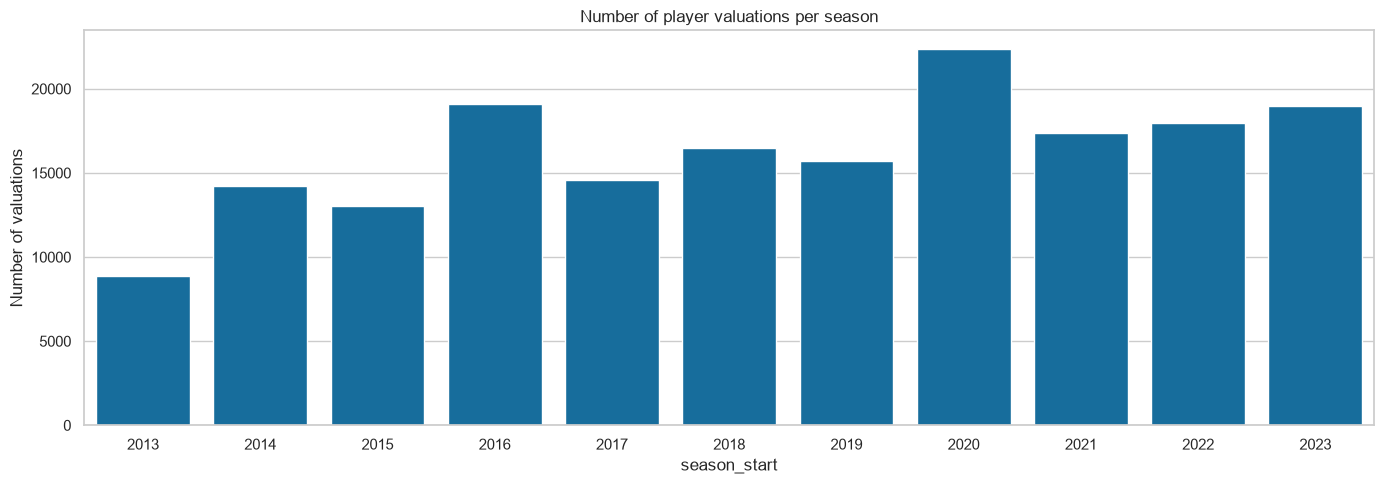

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.set_title("Number of player valuations per season")

sns.countplot(
    data=df_train, x="season_start", order=sorted(df_train["season_start"].unique())
)

ax.set_xlabel("season_start")
ax.set_ylabel("Number of valuations")

plt.tight_layout()
plt.show()

**Observations**: 
- 2013 has noticeably fewer observations than the rest.
- The number of valuations per season ranges from about 9,000 (2013) to 22,000 (2020), with no missing seasons. The count rises and dips from season to season rather than growing steadily. 
- This is consistent with how Transfermarkt produces valuations: in bursts, as new leagues are added and player lists are updated. 

**Decision:** Keep `season_start` and all seasons as they are.

We now plot the distribution of `market_value_in_eur_log1p` for each `season_start` to check whether market values shift over time.

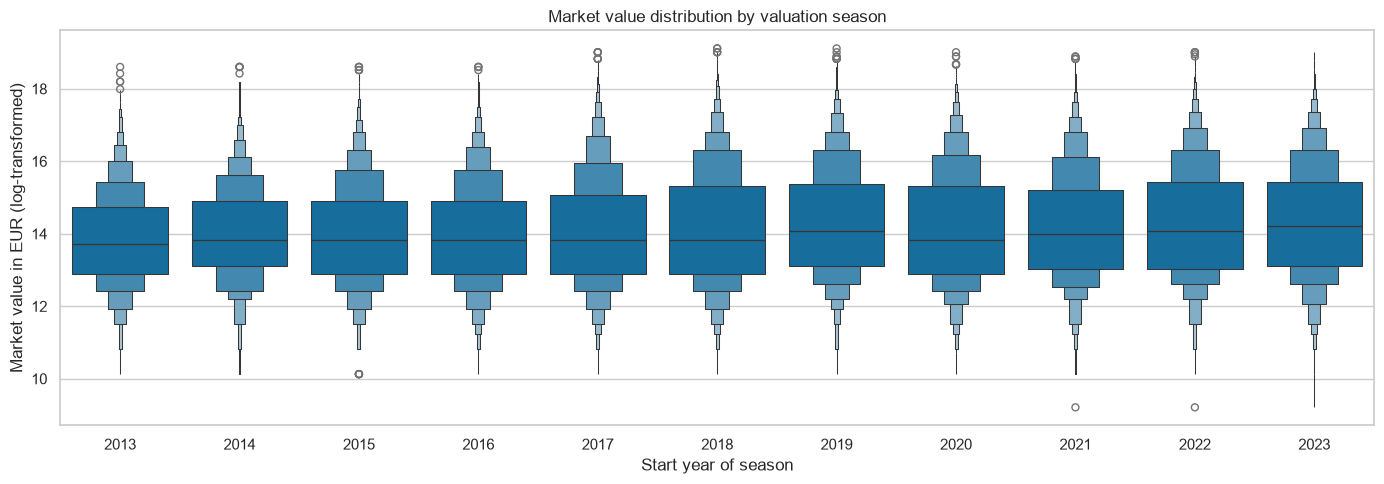

In [21]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.set_title("Market value distribution by valuation season")

sns.boxenplot(
    data=df_train,
    x="season_start",
    y="market_value_in_eur_log1p",
    order=sorted(df_train["season_start"].unique()),
)

ax.set_xlabel("Start year of season")
ax.set_ylabel("Market value in EUR (log-transformed)")

plt.tight_layout()
plt.show()

**Observations**: 
- The distributions are very similar across seasons, with medians between about 13.7 and 14.2 on the log scale. 
- There is a slight upward drift from 2013 to 2023, mostly in the median and upper quartile, and the spread stays roughly the same. Every season has a long right tail, with a few players valued above 18 (log scale), and a handful of low outliers in 2015, 2021 and 2022. 
- Since every season has thousands of valuations, these comparisons are reliable and are not driven by small samples.

**Decision:** Keep `season_start` as a feature, since it carries a weak upward trend in market value. Treat it as numeric rather than categorical, since the change over time is gradual.

#### Effects of categorical features: `league_id`, `position`, `foot`

We now run a one-way ANOVA for `league_id`, `position` and `foot` and compute eta squared to compare how strongly they affect market value.

In [23]:
def eta_squared(df, category, target):
    groups = df.groupby(category)[target]
    grand_mean = df[target].mean()
    ss_between = (groups.count() * (groups.mean() - grand_mean) ** 2).sum()
    ss_total = ((df[target] - grand_mean) ** 2).sum()
    return ss_between / ss_total


def anova_table(df, categories, target):
    rows = []
    for cat in categories:
        sub = df[[cat, target]].dropna()
        samples = [g[target].values for _, g in sub.groupby(cat)]
        f_stat, p_value = stats.f_oneway(*samples)
        rows.append(
            {
                "feature": cat,
                "n_groups": len(samples),
                "F": f_stat,
                "p_value": p_value,
                "eta_squared": eta_squared(sub, cat, target),
            }
        )
    return pd.DataFrame(rows).sort_values("eta_squared", ascending=False)


anova_table(
    df_train,
    [
        "league_id",
        "position",
        "foot",
    ],
    "market_value_in_eur_log1p",
)

,feature,n_groups,F,p_value,eta_squared
0,league_id,15,6437.774574,0.000000e+00,0.335336
2,foot,4,727.318678,0.000000e+00,0.012066
1,position,4,470.317668,1.969144e-304,0.007836


**Observations**:

- Because of the large sample size, all p-values are effectively zero, so eta squared is used to compare the features instead. `eta_squared` by feature:
  - `league_id`: eta squared approx. 0.34, so the league alone explains about a third of the variance in `market_value_in_eur_log1p`. This is a large effect.
  - `foot`: eta squared approx. 0.012, so it explains only about 1% of the variance. This is small, and `league_id` is roughly 28 times stronger.
  - `position`: eta squared approx. 0.008, so it explains less than 1% of the variance. This is small, and `league_id` is roughly 43 times stronger.
- Among the categorical features examined, league therefore has the strongest effect on market value.

**Decision:** Keep `league_id` as the main categorical feature. Keep `foot` and `position` as minor features, since their effect is weak but they cost little to include.

#### `league_id`

We now plot the distribution of `market_value_in_eur_log1p` for each `league_id`, ordered by median market value, to see how much a player's domestic league affects their value. 

Empirical evidence suggests that a mid-tier player in a top league like the Premier League is not valued the same as an equivalent player in a lower-ranking league, so we expect the league to carry useful information beyond the player's own performance.

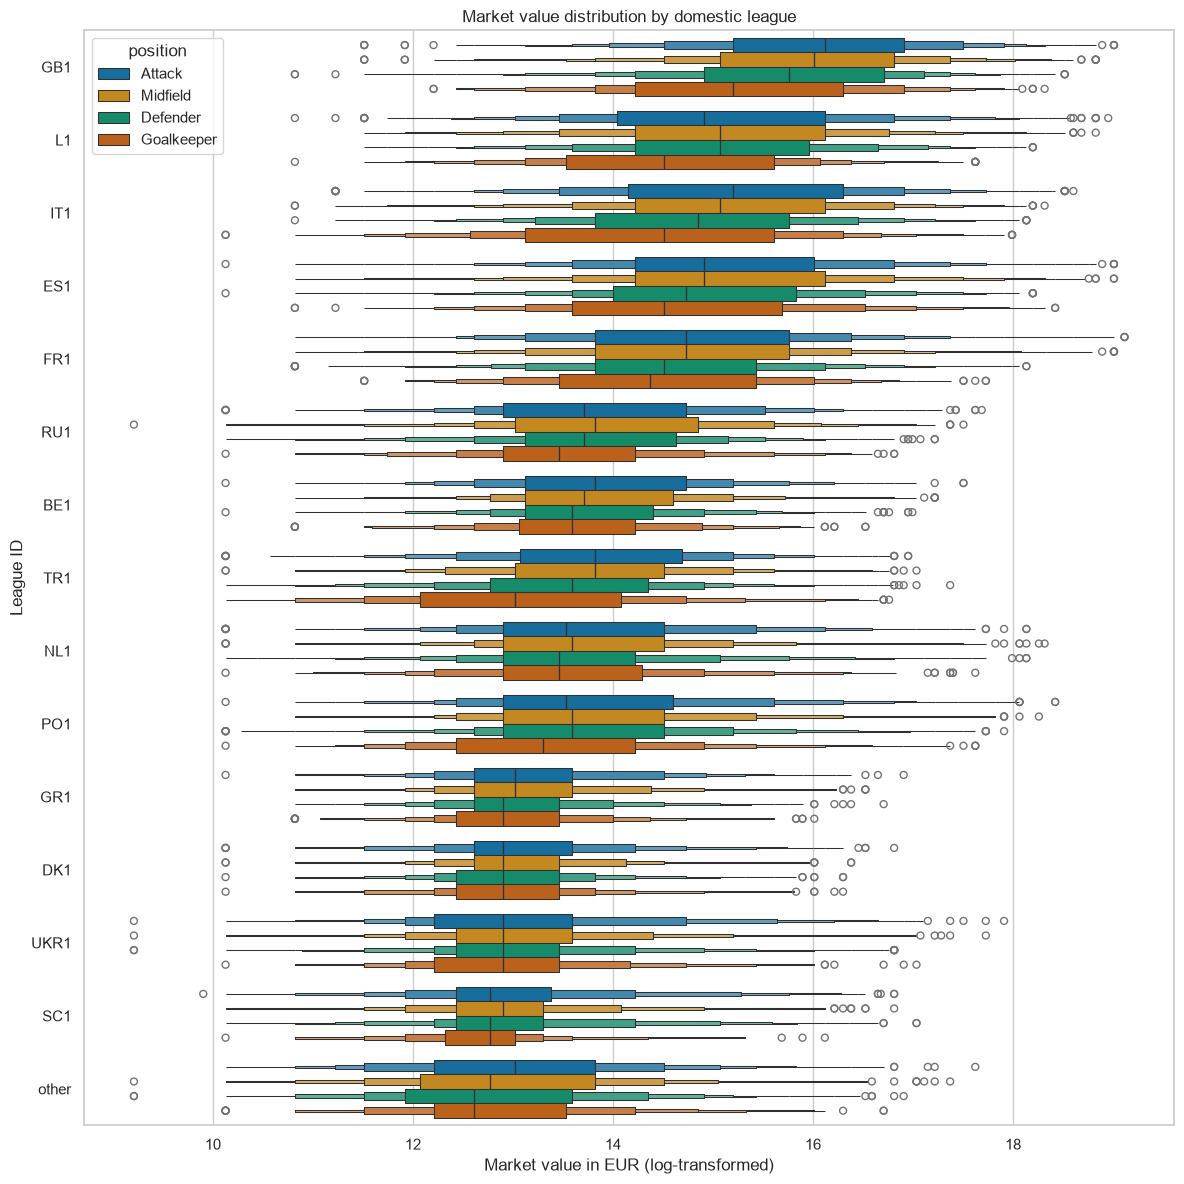

In [28]:
fig, ax = plt.subplots(figsize=(12, 12))

ax.set_title("Market value distribution by domestic league")

sns.boxenplot(
    data=df_train,
    x="market_value_in_eur_log1p",
    y="league_id",
    hue="position",
    hue_order=["Attack", "Midfield", "Defender", "Goalkeeper"],
    order=(
        df_train.groupby("league_id")["market_value_in_eur_log1p"]
        .median()
        .sort_values(ascending=False)
        .index
    ),
)

ax.set_ylabel("League ID")
ax.set_xlabel("Market value in EUR (log-transformed)")

plt.tight_layout()
plt.show()

**Observations**:

- **Market value by league**:
  - Market value differs strongly by league, and the medians fall into three fairly clear groups:
    - **Top tier**: `GB1`, `L1`, `IT1`, `ES1`, and `FR1`. Medians of about 14.7 to 15.9 on the log scale (roughly 2.4M to 8M EUR).
    - **Middle tier**: `RU1`, `BE1`, `TR1`, `NL1`, and `PO1`. Medians of about 13.5 to 13.7 (roughly 0.7M to 0.9M EUR).
    - **Bottom tier**: `GR1`, `DK1`, `UKR1`, `SC1`. and `other`. Medians of about 12.8 to 13.0 (roughly 0.35M to 0.45M EUR).
  - The top tier matches Europe's "top five" (Premier League, Bundesliga, Serie A, La Liga and Ligue 1), so the data agrees with the common assessment.
  - The ranking within the top five is not uniform. GB1 has the highest median (approx. 15.9), about 22 times the median of the lowest leagues (SC1 and `other`, approx. 12.8), which is a bit more than one order of magnitude.
  - The top leagues have wider spreads and reach the highest values (above 18, or about 65M EUR and up), whereas leagues like GR1, DK1, UKR1 and SC1 are narrower and concentrated at lower values.
  - Across all leagues, values span roughly 9 to 19 on the log scale, about four orders of magnitude (from around 10k EUR to over 100M EUR). Every league has a long right tail and a few outliers at both ends.

- **Market value by position**:
  - Splitting by `position` shows that the league ordering is the same for all four positions. The gaps between leagues are much larger than the gaps between positions within a league, so the league effect does not depend on position.
  - Within a league, goalkeepers tend to have the lowest median, while attackers and midfielders have the highest and defenders sit in between.
  - The gap is largest in the top tier (e.g. GB1, where goalkeepers are about 0.9 log units below attackers, a factor of about 2.5 in EUR) and almost disappears in the bottom tier, where the four positions have nearly identical medians.
  - This is consistent with the low eta squared of `position` (approx. 0.008) where position does shift values, mostly in the top leagues, but explains far less than league.

Based on the three groups seen in the previous plot, we define `league_tier` (`top5`, `mid5` and `rest`).

In [13]:
df_train["league_tier"] = df_train["league_id"].apply(
    lambda x: (
        "top5"
        if x in ("GB1", "L1", "IT1", "ES1", "FR1")
        else "mid5" if x in ("RU1", "BE1", "TR1", "NL1", "PO1") else "rest"
    )
)

We now plot the density of `market_value_in_eur_log1p` for each tier, together with the overall distribution, to see how much of the overall shape is explained by the league.

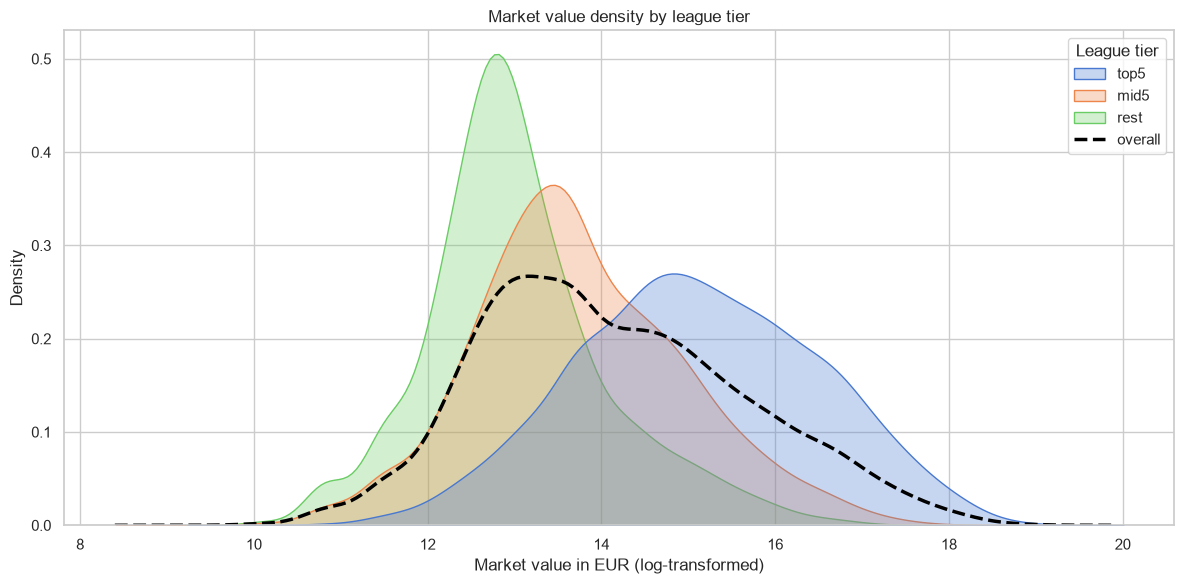

In [14]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.kdeplot(
    data=df_train,
    x="market_value_in_eur_log1p",
    hue="league_tier",
    hue_order=["top5", "mid5", "rest"],
    common_norm=False,
    fill=True,
    alpha=0.3,
    palette="muted",
    bw_adjust=2.0,
    ax=ax,
)
leg = ax.get_legend()

sns.kdeplot(
    data=df_train,
    x="market_value_in_eur_log1p",
    color="black",
    linewidth=2.5,
    linestyle="--",
    bw_adjust=2.0,
    ax=ax,
)

ax.legend(
    [*leg.legend_handles, ax.lines[-1]],
    [*(t.get_text() for t in leg.get_texts()), "overall"],
    title="League tier",
)
ax.set(
    title="Market value density by league tier",
    xlabel="Market value in EUR (log-transformed)",
    ylabel="Density",
)

plt.tight_layout()
plt.show()

**Observations**:

- Each league tier forms its own roughly bell-shaped curve, with peaks at about 14.8 for `top5`, 13.4 for `mid5` and 12.8 for `rest`.
- The curves are clearly shifted from each other, and `top5` is also the widest, with a longer right tail reaching above 18.
- The overall distribution is the combination of these three curves, which explains why it is broad and right-skewed with a shoulder around 14 rather than a single clean bell.
- League tier therefore explains a large part of the shape of the overall distribution, so league has a strong effect on market value.

**Decision:** Keep `league_tier` as a feature, as it captures most of the league effect with only three categories.

The density plot shows the bulk of the distribution, so we now check the right tail to find the league tiers where the most valuable players of each season come from. 

For each season, we keep each player's peak valuation and take the top 300 players, then plot the share of each `league_tier` among them.

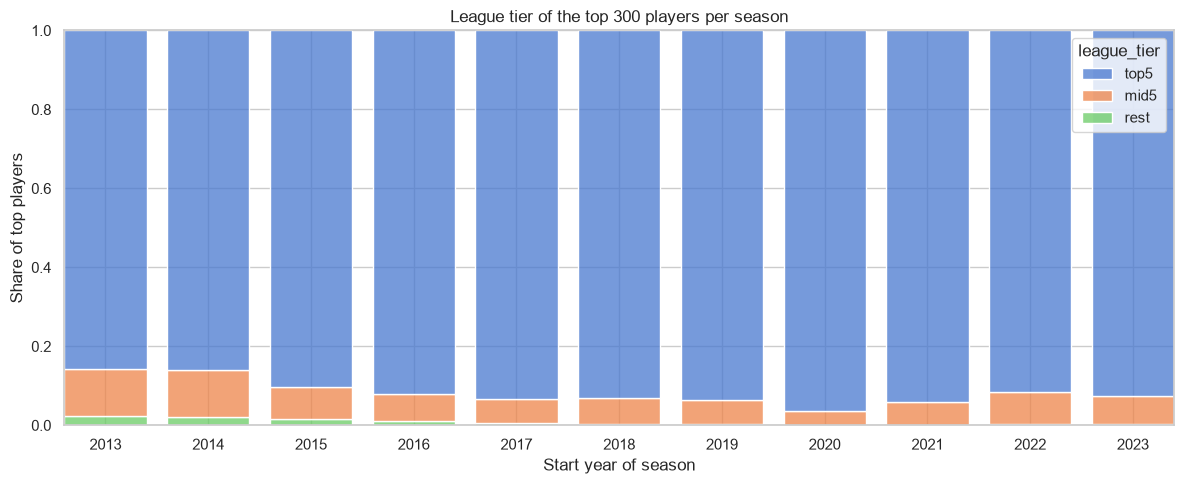

In [33]:
TOP_PLAYERS_PER_YEAR = 300

df_top_players = (
    df_train.sort_values("market_value_in_eur_log1p", ascending=False)
    .drop_duplicates(["player_id", "season_start"])
    .groupby("season_start")
    .head(TOP_PLAYERS_PER_YEAR)
)

fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=df_top_players,
    x="season_start",
    hue="league_tier",
    hue_order=["top5", "mid5", "rest"],
    multiple="fill",
    discrete=True,
    shrink=0.8,
    palette="muted",
    ax=ax,
)

ax.set_xticks(sorted(df_top_players["season_start"].unique()))
ax.set(
    title=f"League tier of the top {TOP_PLAYERS_PER_YEAR} players per season",
    xlabel="Start year of season",
    ylabel="Share of top players",
)

plt.tight_layout()
plt.show()

**Observations**:

- `top5` players make up the large majority of the most valuable players in every season, at about 86% in 2013 and 2014 and about 90% to 96% from 2015 onward. The peak is in 2020, at about 96%.
- `mid5` players account for the rest of the top 300, with a share of about 12% in 2013 and 2014 that falls to about 3% to 8% in later seasons.
- `rest` players are almost absent. They are about 2% of the top 300 in 2013 and 2014, and close to 0% from 2017 onward.
- The tier shares are stable from 2016 onward, apart from small changes in `mid5`. The only visible shift is in the earliest seasons, where the top 300 is less dominated by `top5`.
- The extreme values are therefore a top-five phenomenon, which matches the density plot, where only `top5` has a long right tail above 17.

**Decision:** 
- Keep `league_id` as the league feature, since it separates where the most valuable players come from. `league_tier` is only used here to group the leagues for visualization. 
- Because the shares are stable over time, we do not need to add an interaction between league and `season_start`.

#### Feature engineering: `age`

We define a new feature named `age`, the player's age at the time of the valuation in years. It is computed as the number of days between `date_of_birth` and the valuation `date`, divided by 365.25 to account for leap years.

In [15]:
df_train["age"] = (
    pd.to_datetime(df_train["date"]) - pd.to_datetime(df_train["date_of_birth"])
).dt.days / 365.25

We now plot the distribution of `age`, rounded up to whole years, to see which ages are well represented in the data and whether there are any unusual values.

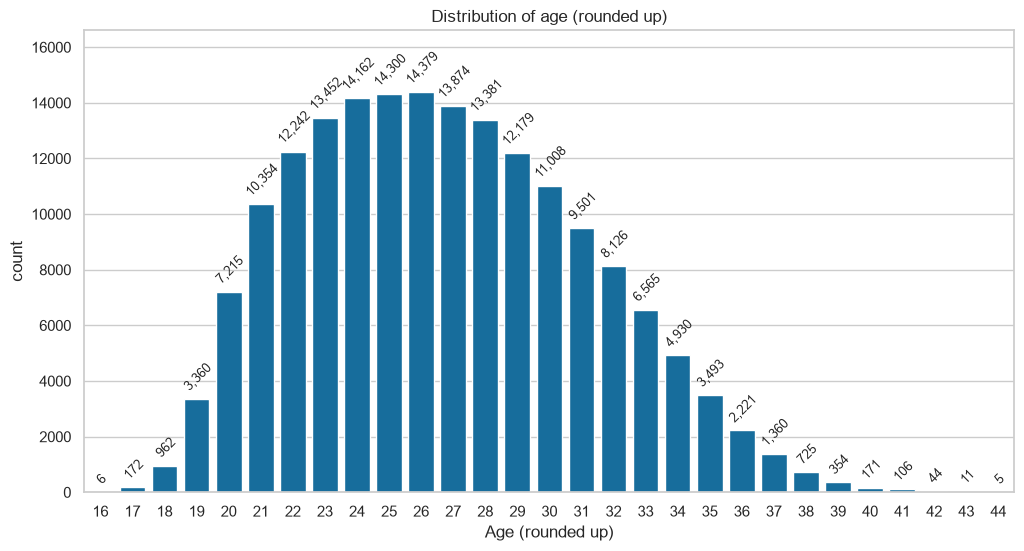

In [35]:
fig, ax = plt.subplots(figsize=(12, 6))
df_age = df_train.assign(age_bin=np.ceil(df_train["age"]).astype(int))

sns.countplot(
    data=df_age.assign(age_bin=np.ceil(df_train["age"]).astype(int)),
    x="age_bin",
    ax=ax,
)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{int(height):,}",
            (p.get_x() + p.get_width() / 1.8, height),
            ha="center",
            va="bottom",
            fontsize=9,
            rotation=45,
            xytext=(0, 4),
            textcoords="offset points",
        )

ax.set_title("Distribution of age (rounded up)")
ax.set_xlabel("Age (rounded up)")
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)

plt.show()

**Observations**:

- The distribution is unimodal and peaks at ages 24 to 26, with about 14,000 valuations each (26 is the highest, at 14,379).
- Most valuations are of players in their twenties. Ages 21 to 30 make up about 72% of the data, and the median falls in the 26 bin.
- The shape is slightly right-skewed. The count rises steeply from 18 (962) to 22 (about 12,000), but declines more slowly after the peak, from about 13,000 at 28 to about 3,500 at 35.
- The tails are thin. Ages 18 and below make up under 1% of the data, and so do ages 38 and above, with only a handful of valuations at 16 and from 42 on.
- There are no impossible values, such as negative ages or ages above 45.

**Decision:** Keep `age` as a numeric feature and do not remove the extreme ages, since they are plausible and few.

Market value is likely to be non-linear in age (peaking in the mid-20s), so we check its relationship with `market_value_in_eur_log1p` next.

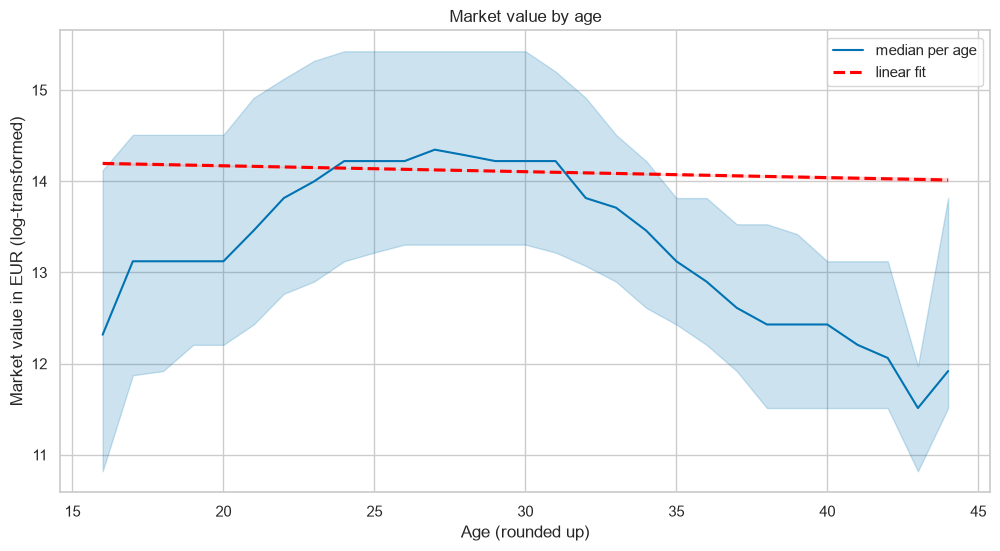

In [36]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=df_age,
    x="age_bin",
    y="market_value_in_eur_log1p",
    estimator="median",
    errorbar=("pi", 50),
    label="median per age",
    ax=ax,
)
sns.regplot(
    data=df_age,
    x="age_bin",
    y="market_value_in_eur_log1p",
    scatter=False,
    color="red",
    line_kws={"linestyle": "--"},
    label="linear fit",
    ax=ax,
)

ax.set(
    title="Market value by age",
    xlabel="Age (rounded up)",
    ylabel="Market value in EUR (log-transformed)",
)
ax.legend()
plt.show()

**Observations**:

- The relationship is clearly non-linear and follows an inverted U shape. The median rises from about 13.1 at ages 17 to 20 to a plateau of about 14.2 to 14.3 between ages 24 and 31, with a peak at about 27 (roughly 1.7M EUR). It then falls steadily to about 12.4 by ages 38 to 40 (roughly 0.24M EUR).
- The decline after 31 is steeper than the rise before 24. The median loses about 1.8 log units between 31 and 40, which is a factor of about 6 in EUR.
- The linear fit is almost flat, falling only from about 14.2 to 14.0 across the whole range. A straight line would suggest that age has almost no effect, which is misleading because the rise and the fall cancel out.
- The interquartile band is wide (about 2 log units at the peak) and overlaps across most ages, so age alone does not determine market value. It shifts the typical value, and other features explain the spread within each age.
- The curve is noisy at the ends (ages 16 and 43 to 44), where there are very few valuations, so these points should not be interpreted.

**Decision:** Keep `age`, since it has a strong effect even though it is not linear. Tree-based models can learn the shape directly.

#### Feature engineering `avg_minutes_per_appearance` and `*_per_90m`

We define per-90-minute versions of the performance statistics (`goals_per_90m`, `assists_per_90m`, `goals_conceded_per_90m` and `clean_sheets_per_90m`) and the average minutes played per appearance (`avg_minutes_per_appearance`). This follows traditional football analysis, where players are compared by their output per 90 minutes (one full match) rather than by season totals. There are also three practical reasons:

- **Playing time distorts totals:** A player with 10 goals in 3,000 minutes is more productive than one with 10 goals in 1,000 minutes, but the raw totals can't show it. Rates make players with very different playing time comparable.
- **Less overlap with playing time:** Raw totals mostly measure how much a player played, which `minutes_per_365d` already captures. Rates isolate the quality of the output.
- **Role information:** `avg_minutes_per_appearance` separates regular starters (close to 90 minutes) from substitutes (a short time per appearance), which reflects how much the coach relies on the player.

The defensive statistics (`goals_conceded_per_90m` and `clean_sheets_per_90m`) are most informative for goalkeepers and defenders.

In [42]:
for stat in ["goals", "assists", "goals_conceded", "clean_sheets"]:
    df_train[f"{stat}_per_90m"] = df_train[f"{stat}_per_365d"] / df_train["minutes_per_365d"] * 90

df_train["avg_minutes_per_appearance"] = df_train["minutes_per_365d"] / df_train["n_appearances"]

To check whether the per-90 features add anything beyond the raw `*_per_365d` totals, we plot the median `market_value_in_eur_log1p` across deciles of each stat, split by playing-time tier (terciles of `minutes_per_365d`). Goals and assists exclude goalkeepers and defenders.

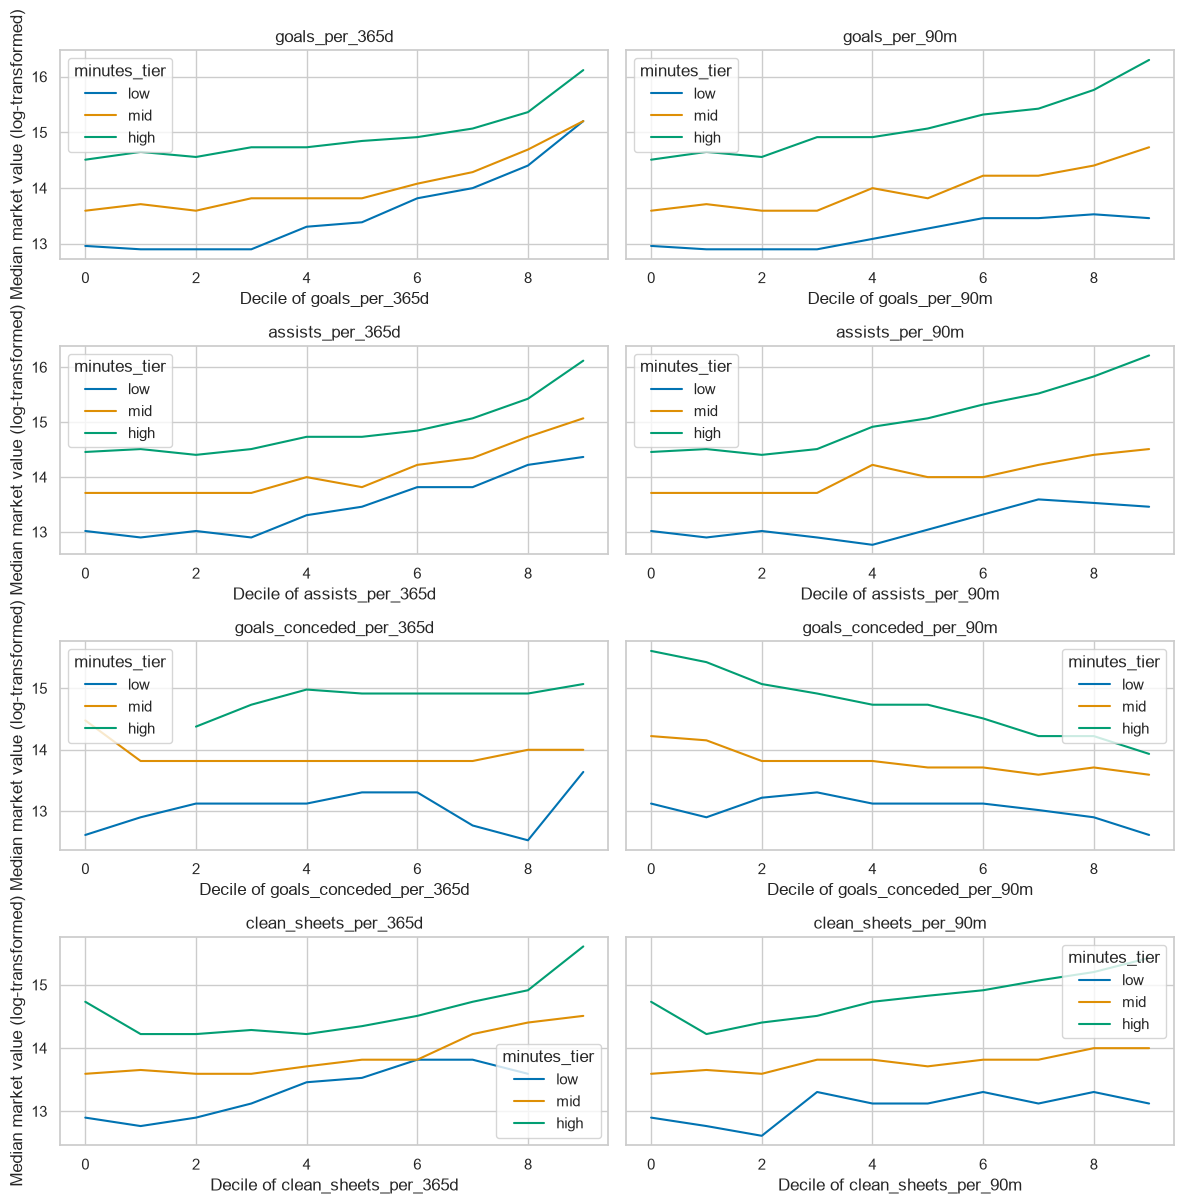

In [46]:
defensive = ["goals_conceded", "clean_sheets"]
stats = ["goals", "assists", *defensive]
is_in_gk_def = df_train["position"].isin(["Goalkeeper", "Defender"])

fig, axes = plt.subplots(len(stats), 2, figsize=(12, 12), sharey="row")

for row, stat in zip(axes, stats):
    df = df_train[is_in_gk_def if stat in defensive else ~is_in_gk_def]
    df = df.assign(minutes_tier=pd.qcut(df["minutes_per_365d"], 3, labels=["low", "mid", "high"]))

    for ax, col in zip(row, [f"{stat}_per_365d", f"{stat}_per_90m"]):
        sns.lineplot(
            data=df.assign(decile=pd.qcut(df[col].rank(method="first"), 10, labels=False)),
            x="decile",
            y="market_value_in_eur_log1p",
            hue="minutes_tier",
            estimator="median",
            errorbar=None,
            ax=ax,
        )
        ax.set(title=col, xlabel=f"Decile of {col}", ylabel="Median market value (log-transformed)")

plt.tight_layout()
plt.show()

**Observations**:

- Playing time matters more than any of these stats. In every panel, the three tiers are separated by about 1 to 1.5 log units, which is a bigger gap than the stat creates within a tier. The `high` tier is worth the most at every decile.
- For `goals_conceded`, per-90 is clearly better than raw.
  - The raw version is flat or erratic, and the `high` tier has no players in the first two deciles, so raw goals conceded mostly reflects how much a player played.
  - The per-90 version declines in all three tiers, most clearly in `high` (from about 15.6 to 13.9). Conceding fewer goals per 90 goes with higher market value.
- For `goals` and `assists`, raw and per-90 look similar in the `high` tier. Both rise by about 1.6 log units across the deciles, so per-90 mainly adds comparability rather than new signal.
- Per-90 is weaker in the `low` tier. For goals and assists, the raw line keeps rising, but the per-90 line flattens after decile 6 (about 13.5). This is the small-sample problem: a goal in a few minutes gives a very high per-90 rate that says little about the player.
- For `clean_sheets`, the picture is mixed. Per-90 is slightly cleaner in the `high` tier, raw is slightly steeper in `mid`, and the `low` tier is noisy for both.

**Decision:** Keep both the raw and per-90 versions, since they carry different information (volume versus efficiency) and the per-90 version is clearly useful for `goals_conceded`. Treat `goals_per_90m` and `assists_per_90m` as noisy for low-minutes players, and let the correlation matrix and the model show how much they add.

#### Effects of numerical features

In [ ]:
target_and_feature_columns = [
    "market_value_in_eur_log1p",
    "age",
    "season_start",
    "height_in_cm",
    "n_appearances",
    "minutes_per_365d",
    "avg_minutes_per_appearance",
    "goals_per_365d",
    "goals_per_90m",
    "assists_per_365d",
    "assists_per_90m",
    "yellow_cards_per_365d",
    "red_cards_per_365d",
    "league_minutes_per_365d",
    "cup_minutes_per_365d",
    "goals_conceded_per_365d",
    "goals_conceded_per_90m",
    "clean_sheets_per_365d",
    "clean_sheets_per_90m",
]

We now compute a Spearman correlation matrix between `market_value_in_eur_log1p` and the numerical features, separately for attackers and midfielders and for defenders and goalkeepers, since the goal and defensive statistics may mean different things for each group. 

Only players with at least 450 minutes in the last 365 days (five full matches) are included, so the per-90 rates are not dominated by tiny samples. Because Spearman is rank-based, it is robust to the skewed distributions.

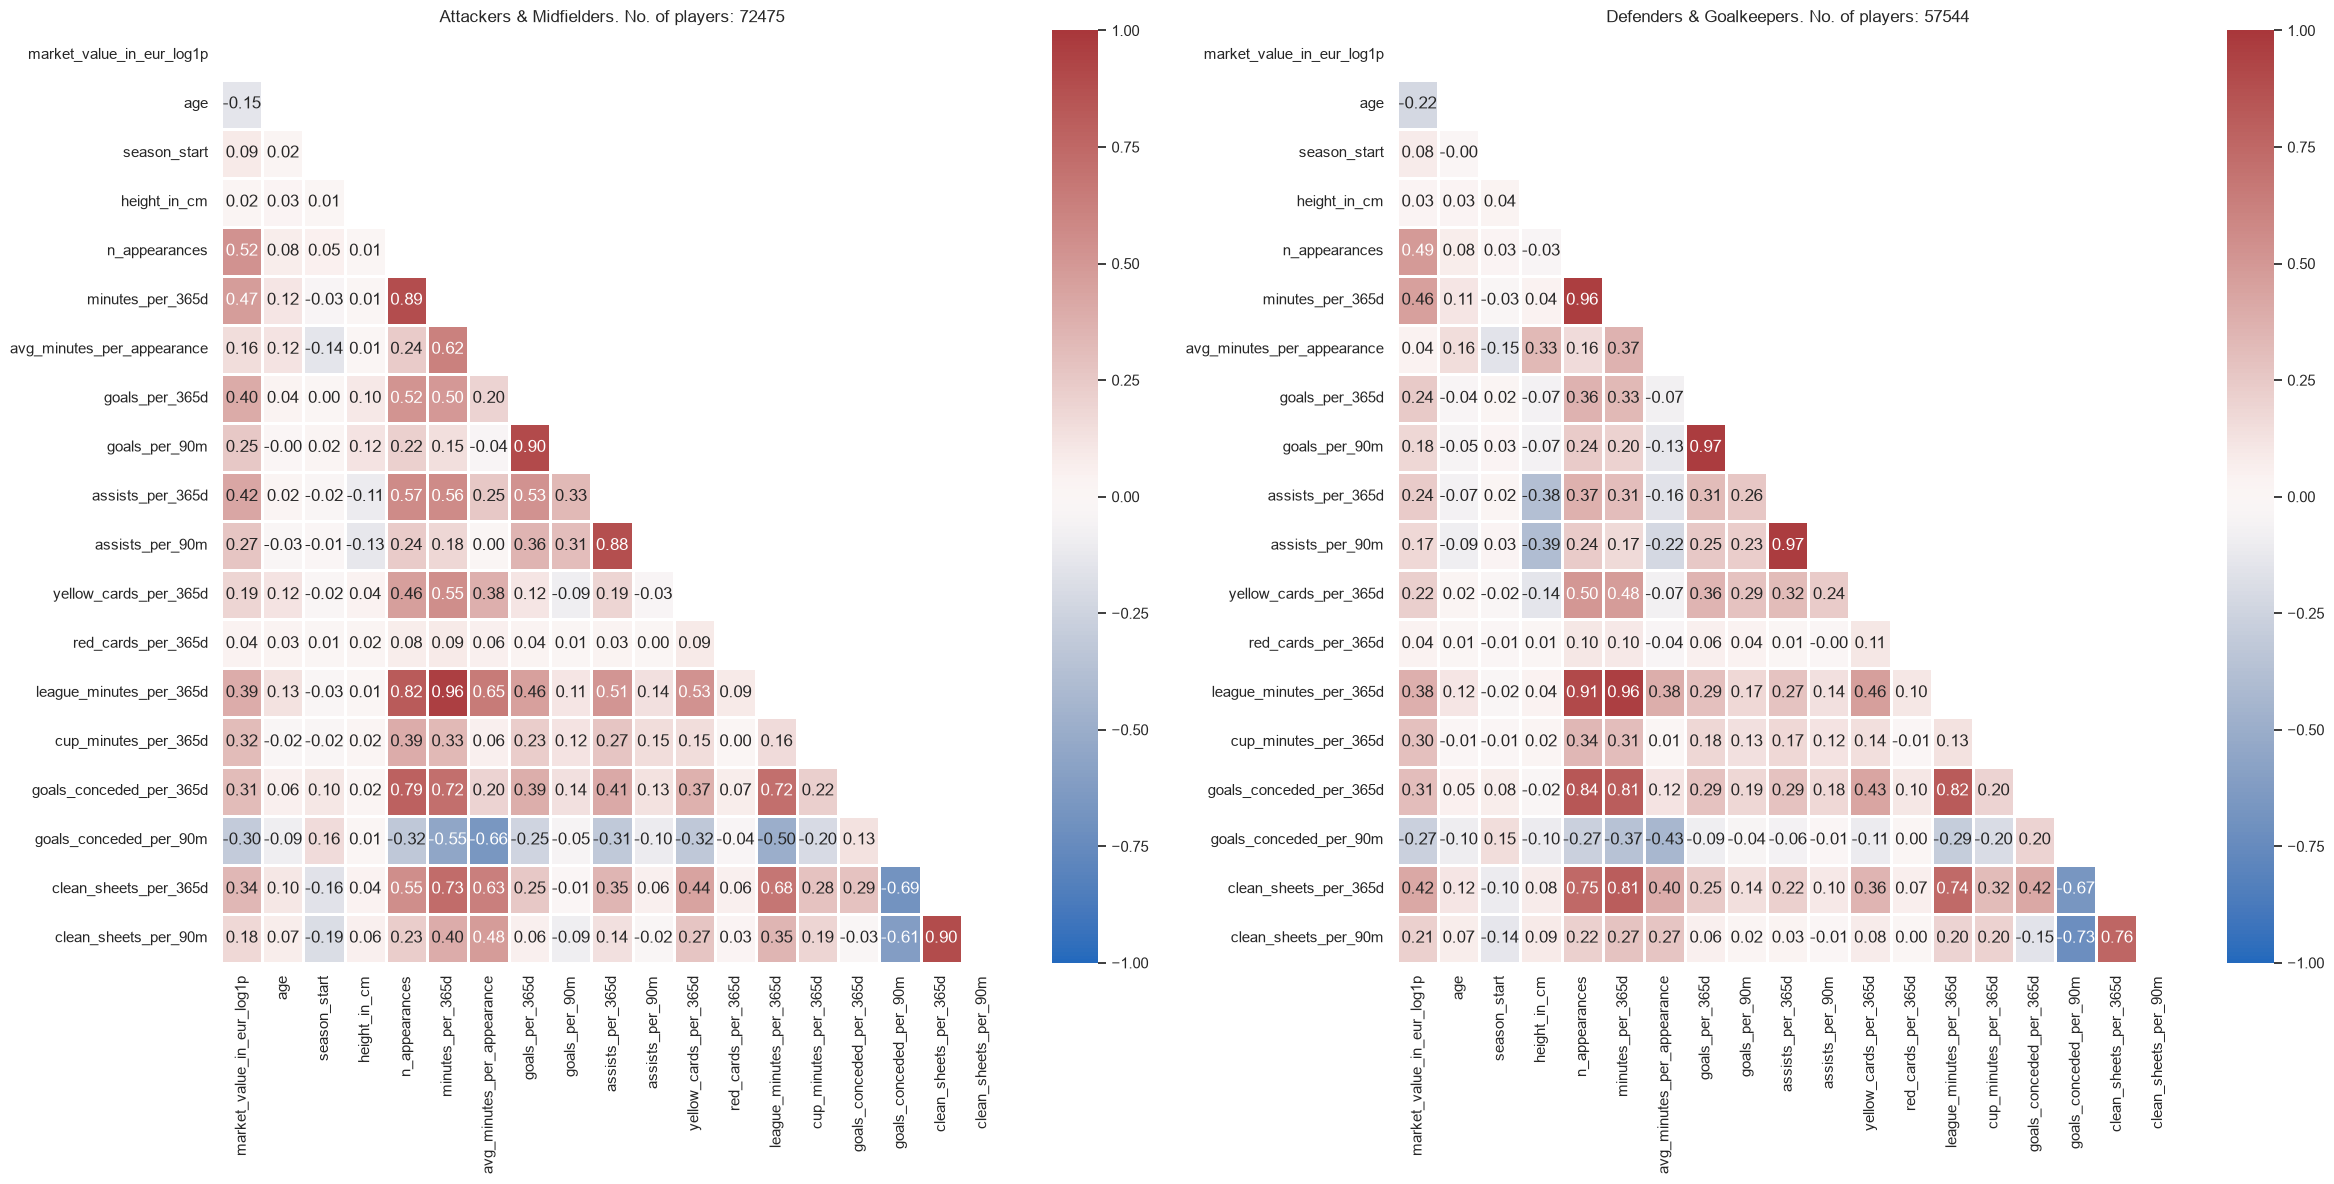

In [ ]:
position_groups = {
    "Attackers & Midfielders": ["Attack", "Midfield"],
    "Defenders & Goalkeepers": ["Defender", "Goalkeeper"],
}

fig, axes = plt.subplots(1, 2, figsize=(24, 12))

for ax, (title, positions) in zip(axes, position_groups.items()):
    df_group = df_train[
        df_train["position"].isin(positions) & (df_train["minutes_per_365d"] >= 450)
    ]

    columns = [col for col in target_and_feature_columns if df_group[col].nunique() > 1]

    corr_matrix = df_group[columns].corr(method="spearman", numeric_only=True)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="vlag",
        vmin=-1,
        vmax=1,
        linewidths=2,
        linecolor="white",
        ax=ax,
    )
    ax.set_title(f"{title}. No. of players: {len(df_group)}")
    ax.grid(False)

plt.tight_layout()
plt.show()

**Observations**:

- Playing time has the strongest correlation with market value in both groups: `n_appearances` (approx. 0.52 and 0.49), `minutes_per_365d` (approx. 0.47 and 0.46) and `league_minutes_per_365d` (approx. 0.39 and 0.38). These three are also highly correlated with each other (approx. 0.82 to 0.96).
- Goals and assists matter more for attackers and midfielders (approx. 0.40 and 0.42, against approx. 0.24 for defenders and goalkeepers). Clean sheets matter more for defenders and goalkeepers (approx. 0.42, against approx. 0.34). This supports splitting the matrix by position group.
- The raw statistics correlate more with market value than their per-90 versions, e.g. `goals_per_365d` at approx. 0.40 against `goals_per_90m` at approx. 0.25 for attackers and midfielders. The raw totals partly carry playing time: raw goals correlate with `minutes_per_365d` at approx. 0.33 to 0.50, the per-90 version at only approx. 0.15 to 0.20.
- For goals and assists, the raw and per-90 versions are almost redundant (approx. 0.88 to 0.97), as in the earlier plot.
- `goals_conceded` flips sign between versions. The raw total is positive (approx. 0.31 in both groups) because it grows with minutes (approx. 0.72 and 0.81). The per-90 rate is negative (approx. -0.30 and -0.27), so conceding fewer goals per 90 goes with a higher value.
- `goals_conceded_per_90m` is about as strong for attackers and midfielders as for defenders and goalkeepers, so it probably reflects the strength of the team more than individual defending.
- `age` has only approx. -0.15 and -0.22, but Spearman captures just the monotonic part of the inverted U shape seen earlier, so it understates the effect.
- `height_in_cm` (approx. 0.02 to 0.03), `red_cards_per_365d` (approx. 0.04), `season_start` (approx. 0.08 to 0.09) and `avg_minutes_per_appearance` (approx. 0.16 and 0.04) are weakly correlated with value.

**Decision:** Keep all features for tree-based models, which handle the redundancy. Keep both versions of `goals_conceded` and `clean_sheets`, since they carry different information. Keep `age` despite its low correlation, and consider dropping `height_in_cm` and `red_cards_per_365d`.

## Conclusions

**Findings:**

Market value is mostly explained by the league a player is in, how much they play, and their age. Performance statistics add less and depend on the player's position.

- League is the strongest categorical feature (eta squared approx. 0.34, against approx. 0.012 for `foot` and approx. 0.008 for `position`). The leagues fall into three groups, and the top five leagues make up about 86% to 96% of the 300 most valuable players each season.
- Playing time is the strongest numerical feature (approx. 0.38 to 0.52 in both position groups).
- Age has an inverted U relationship with market value, peaking at about 27. Its Spearman correlation is low because the relationship is not monotonic.
- Goals and assists matter more for attackers and midfielders, and clean sheets more for defenders and goalkeepers. The per-90 versions add information mainly for `goals_conceded`.
- Season has only a weak upward effect, and the number of valuations per season varies with how Transfermarkt adds leagues and updates players.

**Features to keep:**

| Feature | Decision | Reason |
|---|---|---|
| `league_id` | Keep | Strongest categorical effect (eta squared approx. 0.34) |
| `age` | Keep | Inverted U shape with a peak at about 27. Spearman understates it |
| `n_appearances`, `minutes_per_365d`, `league_minutes_per_365d` | Keep | Strongest numerical features (approx. 0.38 to 0.52). Highly correlated with each other (approx. 0.82 to 0.96), which trees handle |
| `cup_minutes_per_365d` | Keep | Moderate correlation (approx. 0.30 to 0.32) |
| `goals_per_365d`, `assists_per_365d` | Keep | Stronger for attackers and midfielders (approx. 0.40 and 0.42) |
| `goals_per_90m`, `assists_per_90m` | Keep | Almost redundant with the raw versions (approx. 0.88 to 0.97), but less tied to minutes |
| `goals_conceded_per_365d`, `goals_conceded_per_90m` | Keep both | Opposite signs (approx. +0.31 and approx. -0.30), so they carry different information |
| `clean_sheets_per_365d`, `clean_sheets_per_90m` | Keep both | Stronger for defenders and goalkeepers (approx. 0.42 against 0.34) |
| `yellow_cards_per_365d` | Keep | Weak (approx. 0.19 to 0.22), and partly reflects playing time |
| `avg_minutes_per_appearance` | Keep | Weak overall (approx. 0.16 and 0.04), but it separates starters from substitutes |
| `season_start` | Keep | Weak upward trend (approx. 0.08 to 0.09) |
| `position`, `foot` | Keep | Small effects (eta squared approx. 0.008 and 0.012), but cheap to include |
| `height_in_cm`, `red_cards_per_365d` | Consider dropping | Almost no correlation (approx. 0.02 to 0.04) |